# Preparing Embeddings and Creating the kNN

In [14]:
# ! pip3 install opencv-python
# ! pip3 install numpy
# ! pip3 install torch
# ! pip3 install torchvision
# ! pip3 install onnxscript
# ! pip3 install pacmap

In [15]:
import os


In [16]:
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

'1'

In [17]:
import cv2
import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
import pacmap

## Getting Embeddings from ResNet50

In [18]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

In [19]:
def preprocess(img_bgr):
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
    img = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return cv2.dnn.blobFromImage(img)

### Training Data

In [20]:
ROOT = "/Users/shreyanakum/Documents/CS184A/CS184A-Project/"
CSV = ROOT + "DATA_PP/train.csv"
MODEL = ROOT + "Models/ResNetkNN/resnet50_features.onnx"
OUT = ROOT + "Models/ResNetkNN"

In [21]:
df = pd.read_csv("/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/train.csv")

In [22]:
paths = (ROOT + df["filepath"].astype(str)).tolist()

In [23]:
print(paths[:10])

['/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/PMO_08088.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/PEB_01691.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/BLA/BLA_02248.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/EOS_02333.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/NGS_23955.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/BLA/BLA_09671.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/NGS_05475.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/PLM_06374.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/EBO_01550.jpg', '/Users/shreyanakum/Documents/CS184A/CS184A-Project/DATA_PP/normal/MON_02789.jpg']


In [24]:
net = cv2.dnn.readNetFromONNX(MODEL)
net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

[ WARN:0@179.803] global net_impl_backend.cpp:388 setPreferableTarget Targets are not supported by the new graph engine for now


In [25]:
embs, ok_paths = [], []
for n, p in enumerate(paths, start=1):
    img = cv2.imread(p)
    if img is None:
        print(f"Skipping unreadable file: {p}")
        continue
    net.setInput(preprocess(img))
    v = net.forward().flatten().astype(np.float32)
    embs.append(v / (np.linalg.norm(v) + 1e-12)) # L2 norm
    ok_paths.append(p)

embs = np.vstack(embs)
os.makedirs(OUT, exist_ok=True)
np.save(os.path.join(OUT, "embeddings.npy"), embs)
np.save(os.path.join(OUT, "paths.npy"), np.array(ok_paths))
print(f"Saved {embs.shape} embeddings to {OUT}")

Corrupt JPEG data: 354 extraneous bytes before marker 0x08
Corrupt JPEG data: 1765 extraneous bytes before marker 0xd9
Corrupt JPEG data: 699 extraneous bytes before marker 0xd9
Corrupt JPEG data: 1210 extraneous bytes before marker 0xd9


Saved (103538, 2048) embeddings to /Users/shreyanakum/Documents/CS184A/CS184A-Project/Models/ResNetkNN


### PaCMAP View of Embeddings

We want to see if there is actually separable clusters in these embeddings to get a hint at what we should use for the value of $k$. Same with knowing how well kNN should be able to perform.

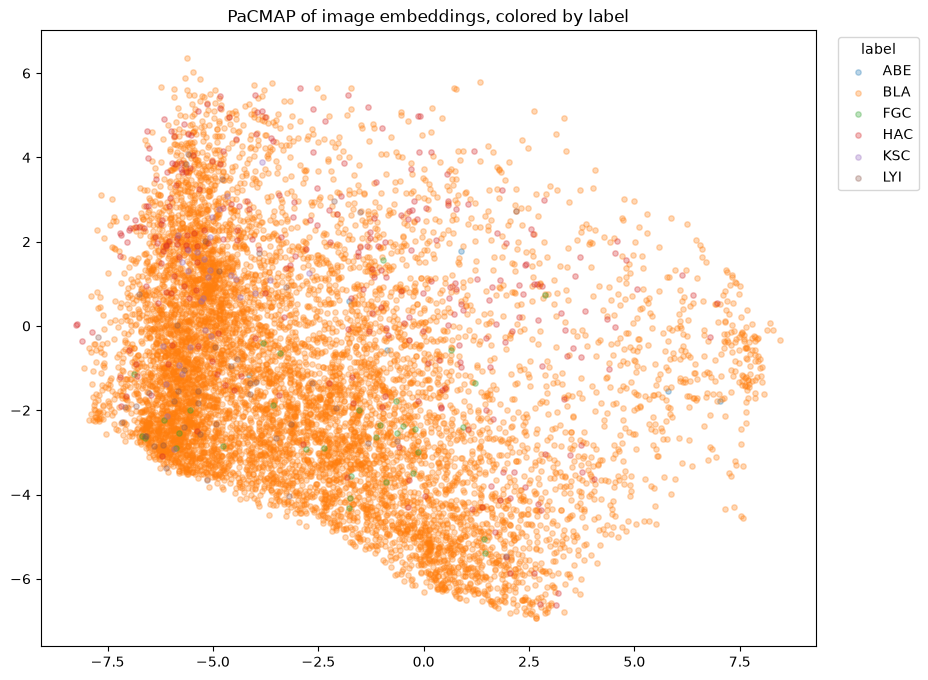

In [29]:
# Match labels to embeddings by path (unreadable images were skipped, so row counts can differ)
label_by_path = dict(zip(ROOT + df["filepath"].astype(str), df["label"]))
labels = np.array([label_by_path[str(p)] for p in paths])

reducer = pacmap.PaCMAP(n_components=2, n_neighbors=None, MN_ratio=0.5, FP_ratio=2.0)
xy = reducer.fit_transform(np.ascontiguousarray(embs, dtype=np.float32), init="pca")  # (N, 2)

fig, ax = plt.subplots(figsize=(10, 8))
for lab in np.unique(labels):
    m = labels == lab
    if lab == 'normal':
        continue
    ax.scatter(xy[m, 0], xy[m, 1], s=15, alpha=0.3, label=str(lab))

ax.set_title("PaCMAP of image embeddings, colored by label")
ax.legend(title="label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [33]:
# Match labels to embeddings by path (unreadable images were skipped, so row counts can differ)
label_by_path = dict(zip(ROOT + df["filepath"].astype(str), df["label"]))
labels = np.array(sorted([label_by_path[str(p)] for p in paths], reverse=True))

print(labels)

['normal' 'normal' 'normal' ... 'ABE' 'ABE' 'ABE']


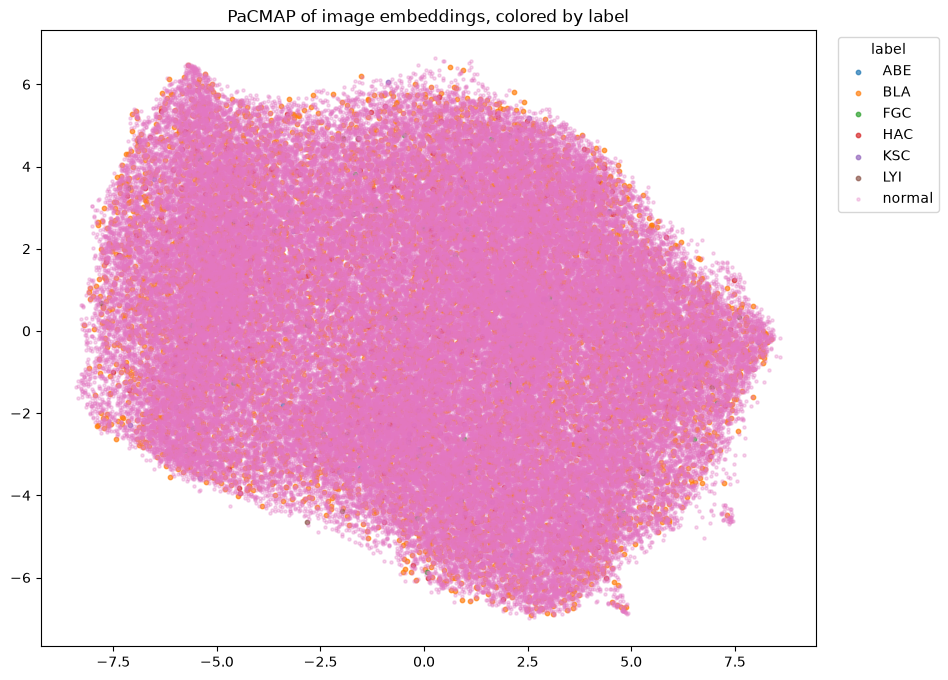

In [36]:

reducer = pacmap.PaCMAP(n_components=2, n_neighbors=None, MN_ratio=0.5, FP_ratio=2.0)
xy = reducer.fit_transform(np.ascontiguousarray(embs, dtype=np.float32), init="pca")  # (N, 2)

fig, ax = plt.subplots(figsize=(10, 8))
for lab in np.unique(labels):
    m = labels == lab
    if lab == 'normal':
        ax.scatter(xy[m, 0], xy[m, 1], s=5, alpha=0.3, label=str(lab))
    else:
        ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.7, label=str(lab))

ax.set_title("PaCMAP of image embeddings, colored by label")
ax.legend(title="label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## Creating the kNN

In [37]:
# ! pip3 install scikit-learn

In [38]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Validation Data Preparation

In [39]:
VAL_CSV = ROOT + "DATA_PP/val.csv"
val_df = pd.read_csv(VAL_CSV)
val_paths = (ROOT + val_df["filepath"].astype(str)).tolist()
print(len(val_paths))

22187


In [40]:
val_embs, val_ok_paths = [], []
for n, p in enumerate(val_paths, start=1):
    img = cv2.imread(p)
    if img is None:
        print(f"Skipping unreadable file: {p}")
        continue
    net.setInput(preprocess(img))
    v = net.forward().flatten().astype(np.float32)
    val_embs.append(v / (np.linalg.norm(v) + 1e-12)) # L2 norm
    val_ok_paths.append(p)

val_embs = np.vstack(val_embs)
np.save(os.path.join(OUT, "val_embeddings.npy"), val_embs)
np.save(os.path.join(OUT, "val_paths.npy"), np.array(val_ok_paths))
print(f"Saved {val_embs.shape} validation embeddings to {OUT}")

Corrupt JPEG data: 1617 extraneous bytes before marker 0xd9
Corrupt JPEG data: 999 extraneous bytes before marker 0xd9


Saved (22187, 2048) validation embeddings to /Users/shreyanakum/Documents/CS184A/CS184A-Project/Models/ResNetkNN


### Load Embeddings & Data

In [41]:
X_train = np.load(os.path.join(OUT, "embeddings.npy"))
train_ok_paths = np.load(os.path.join(OUT, "paths.npy"))

X_val = np.load(os.path.join(OUT, "val_embeddings.npy"))
val_ok_paths = np.load(os.path.join(OUT, "val_paths.npy"))

print(X_train.shape, X_val.shape)

(103538, 2048) (22187, 2048)


In [42]:
# Match labels to embeddings by path (unreadable images were skipped, so row counts can differ)
train_label_by_path = dict(zip(ROOT + df["filepath"].astype(str), df["label"]))
val_label_by_path = dict(zip(ROOT + val_df["filepath"].astype(str), val_df["label"]))

y_train = np.array([train_label_by_path[str(p)] for p in train_ok_paths])
y_val = np.array([val_label_by_path[str(p)] for p in val_ok_paths])

print(pd.Series(y_train).value_counts())
print(pd.Series(y_val).value_counts())

normal    94757
BLA        8381
HAC         286
LYI          45
FGC          33
KSC          30
ABE           6
Name: count, dtype: int64
normal    20305
BLA        1796
HAC          62
LYI          10
FGC           7
KSC           6
ABE           1
Name: count, dtype: int64


### Fitting the kNN

In [43]:
# embeddings are already L2 normalized, so cosine distance works well here
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(X_train, y_train)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U6](7,)","['ABE','BLA','FGC',...,'KSC','LYI','normal']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'cosine'


### Evaluating the kNN

In [44]:
y_pred = knn.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

Accuracy: 0.9364943435345022
              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.72      0.42      0.53      1796
         FGC       0.00      0.00      0.00         7
         HAC       0.50      0.02      0.03        62
         KSC       1.00      0.33      0.50         6
         LYI       0.50      0.10      0.17        10
      normal       0.95      0.99      0.97     20305

    accuracy                           0.94     22187
   macro avg       0.52      0.27      0.31     22187
weighted avg       0.93      0.94      0.93     22187



/Users/shreyanakum/Documents/CS184A/CS184A-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shreyanakum/Documents/CS184A/CS184A-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shreyanakum/Documents/CS184A/CS184A-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to

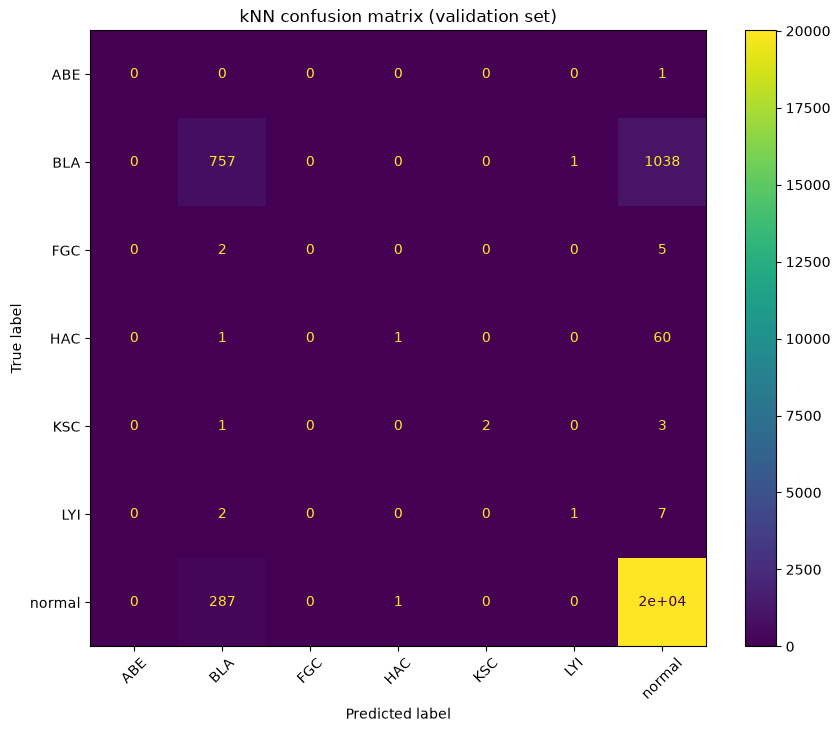

In [45]:
cm = confusion_matrix(y_val, y_pred, labels=knn.classes_)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=knn.classes_).plot(ax=ax, xticks_rotation=45)
ax.set_title("kNN confusion matrix (validation set)")
plt.show()

## Hyperparameter Tuning

In [5]:
import numpy as np
import os

train_embeddings = np.load("embeddings.npy")
train_paths = np.load("paths.npy", allow_pickle=True)

val_embeddings = np.load("val_embeddings.npy")
val_paths = np.load("val_paths.npy", allow_pickle=True)

print("Training embeddings:", train_embeddings.shape)
print("Training paths:", train_paths.shape)

print("Validation embeddings:", val_embeddings.shape)
print("Validation paths:", val_paths.shape)

Training embeddings: (103538, 2048)
Training paths: (103538,)
Validation embeddings: (22187, 2048)
Validation paths: (22187,)


In [7]:
import pandas as pd

ROOT = "../.."
DATA_CSV_LOC = os.path.join(ROOT, "DATA_PP")

train_df = pd.read_csv(os.path.join(DATA_CSV_LOC, "train.csv"))
val_df = pd.read_csv(os.path.join(DATA_CSV_LOC, "val.csv"))

def relative_path(path):
    return "DATA_PP/" + str(path).replace("\\", "/").split("DATA_PP/", 1)[-1]

train_label_map = dict(zip(train_df["filepath"], train_df["label"]))
val_label_map = dict(zip(val_df["filepath"], val_df["label"]))

train_labels = [train_label_map[relative_path(p)] for p in train_paths]
val_labels = [val_label_map[relative_path(p)] for p in val_paths]

print("Training labels:", len(train_labels))
print("Validation labels:", len(val_labels))
print("Classes:", sorted(set(train_labels)))

Training labels: 103538
Validation labels: 22187
Classes: ['ABE', 'BLA', 'FGC', 'HAC', 'KSC', 'LYI', 'normal']


### 1st Experiment: Various number of Neighbors (Different k values)

Testing k = 1, 3, 5, 7, 11, 21

In [8]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score

k_values = [1, 3, 5, 7, 11, 21]

neighbors = NearestNeighbors(
    n_neighbors=max(k_values),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

neighbors.fit(train_embeddings)

distances, indices = neighbors.kneighbors(val_embeddings)

knn_results = []

for k in k_values:
    predictions = []

    for row in indices[:, :k]:
        labels = [train_labels[i] for i in row]
        prediction = max(set(labels), key=labels.count)
        predictions.append(prediction)

    accuracy = accuracy_score(val_labels, predictions)
    macro_f1 = f1_score(
        val_labels, predictions,
        average="macro",
        labels=sorted(set(train_labels)),
        zero_division=0
    )

    knn_results.append({
        "k": k,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

results_df = pd.DataFrame(knn_results)
display(results_df)

,k,Accuracy,Macro F1
0,1,0.914950,0.399920
1,3,0.933700,0.326416
2,5,0.936404,0.315419
3,7,0.937441,0.309481
4,11,0.936720,0.279534
5,21,0.935368,0.203243


### 2nd Experiment: Neighbor Weighting (Weighted vs non-weighted)

In [9]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

k_values = [1, 3, 5, 7, 11, 21]
classes = sorted(set(train_labels))

# Convert labels into numeric class indices
class_to_idx = {c: i for i, c in enumerate(classes)}
train_y = np.array([class_to_idx[c] for c in train_labels])
val_y = np.array([class_to_idx[c] for c in val_labels])

weight_results = []

for k in k_values:
    neighbor_labels = train_y[indices[:, :k]]
    neighbor_distances = distances[:, :k]

    for weighting in ["uniform", "distance"]:
        predictions = []

        for labels, dists in zip(neighbor_labels, neighbor_distances):
            if weighting == "uniform":
                votes = np.bincount(labels, minlength=len(classes))
            else:
                # Give closer neighbors more weight
                if np.any(dists == 0):
                    weights = (dists == 0).astype(float)
                else:
                    weights = 1.0 / dists

                votes = np.bincount(
                    labels,
                    weights=weights,
                    minlength=len(classes)
                )

            predictions.append(np.argmax(votes))

        accuracy = accuracy_score(val_y, predictions)
        macro_f1 = f1_score(
            val_y,
            predictions,
            labels=list(range(len(classes))),
            average="macro",
            zero_division=0
        )

        weight_results.append({
            "k": k,
            "Weighting": weighting,
            "Accuracy": accuracy,
            "Macro F1": macro_f1
        })

weight_results_df = pd.DataFrame(weight_results)
display(weight_results_df)

,k,Weighting,Accuracy,Macro F1
0,1,uniform,0.914950,0.399920
1,1,distance,0.914950,0.399920
2,3,uniform,0.933700,0.324593
3,3,distance,0.933700,0.348900
4,5,uniform,0.936494,0.313722
5,5,distance,0.936449,0.315642
6,7,uniform,0.937396,0.309729
7,7,distance,0.937486,0.309714
8,11,uniform,0.936945,0.280162
9,11,distance,0.936900,0.279934


We tested different k values (1, 3, 5, 7, 11, and 21) and compared uniform and distance-weighted voting. The best result was k = 1, with a validation macro F1 of 0.3999 and accuracy of 91.50%. Larger k values generally had higher accuracy but lower macro F1, likely because normal cells make up most of the dataset. Distance weighting improved some results, especially at k = 3, but did not outperform k = 1. We selected k = 1 with uniform voting for our final kNN model.

## Evaluate on Validation Set

Best k: 1
              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.51      0.49      0.50      1796
         FGC       0.50      0.29      0.36         7
         HAC       0.17      0.16      0.17        62
         KSC       0.80      0.67      0.73         6
         LYI       0.08      0.10      0.09        10
      normal       0.95      0.96      0.95     20305

    accuracy                           0.91     22187
   macro avg       0.43      0.38      0.40     22187
weighted avg       0.91      0.91      0.91     22187



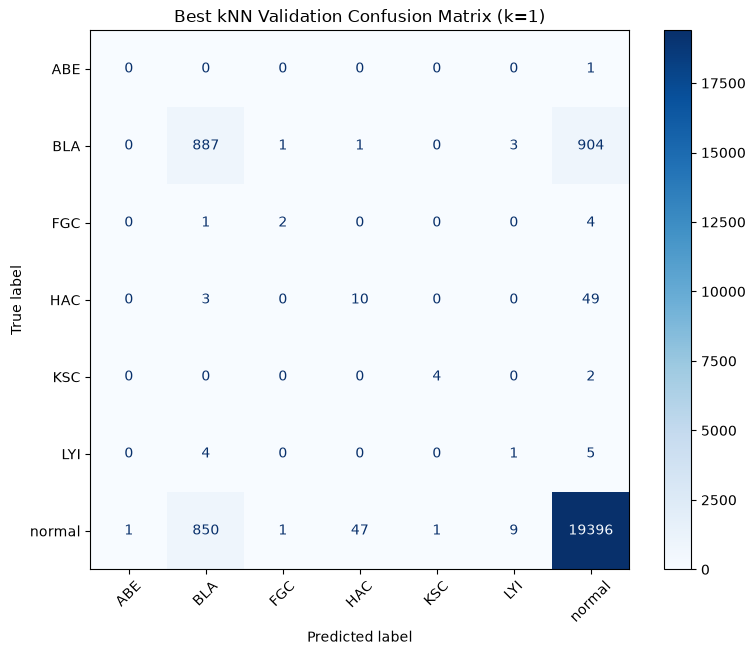

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Best configuration: k = 1
best_k = 1

best_knn_preds = train_y[indices[:, 0]]

print("Best k:", best_k)

print(classification_report(
    val_y,
    best_knn_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    val_y,
    best_knn_preds,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Best kNN Validation Confusion Matrix (k=1)")
plt.xticks(rotation=45)
plt.show()

## Test Evaluation

In [21]:
import os
import cv2
import numpy as np
import pandas as pd

# Paths
ROOT = os.path.abspath("../..")
MODEL = os.path.join(ROOT, "Models/ResNetkNN/resnet50_features.onnx")
TEST_CSV = os.path.join(ROOT, "DATA_PP/test.csv")

# Load test image paths
test_df = pd.read_csv(TEST_CSV)
test_paths = [
    os.path.join(ROOT, p)
    for p in test_df["filepath"]
]

# Load pretrained ResNet50
net = cv2.dnn.readNetFromONNX(MODEL)
net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

# Use Shreya's original preprocessing
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess(img_bgr):
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
    img = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return cv2.dnn.blobFromImage(img)

# Extract test embeddings
test_embs = []
test_ok_paths = []

for n, path in enumerate(test_paths, start=1):
    img = cv2.imread(path)

    if img is None:
        print("Skipping unreadable image:", path)
        continue

    net.setInput(preprocess(img))
    v = net.forward().flatten().astype(np.float32)

    # L2 normalization
    v = v / (np.linalg.norm(v) + 1e-12)

    test_embs.append(v)
    test_ok_paths.append(path)

    if n % 1000 == 0:
        print(f"Processed {n}/{len(test_paths)} images")

test_embs = np.vstack(test_embs)

# Save the embeddings for future use
np.save("test_embeddings.npy", test_embs)
np.save("test_paths.npy", np.array(test_ok_paths))

print("Test embeddings:", test_embs.shape)
print("Test paths:", len(test_ok_paths))

[ WARN:0@47409.263] global net_impl_backend.cpp:388 setPreferableTarget Targets are not supported by the new graph engine for now


Processed 1000/22187 images
Processed 2000/22187 images
Processed 3000/22187 images
Processed 4000/22187 images
Processed 5000/22187 images
Processed 6000/22187 images
Processed 7000/22187 images


Corrupt JPEG data: 979 extraneous bytes before marker 0xd9


Processed 8000/22187 images
Processed 9000/22187 images
Processed 10000/22187 images
Processed 11000/22187 images
Processed 12000/22187 images
Processed 13000/22187 images
Processed 14000/22187 images
Processed 15000/22187 images
Processed 16000/22187 images
Processed 17000/22187 images


Corrupt JPEG data: 806 extraneous bytes before marker 0xd9


Processed 18000/22187 images
Processed 19000/22187 images
Processed 20000/22187 images


Corrupt JPEG data: 1117 extraneous bytes before marker 0xd9


Processed 21000/22187 images
Processed 22000/22187 images
Test embeddings: (22187, 2048)
Test paths: 22187


Test Accuracy: 0.9125
Test Macro F1: 0.3389

Classification Report:
              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.50      0.48      0.49      1796
         FGC       0.20      0.14      0.17         7
         HAC       0.14      0.15      0.14        61
         KSC       0.60      0.50      0.55         6
         LYI       0.06      0.10      0.08        10
      normal       0.95      0.95      0.95     20306

    accuracy                           0.91     22187
   macro avg       0.35      0.33      0.34     22187
weighted avg       0.91      0.91      0.91     22187



/Users/janani/jupyter-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/janani/jupyter-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/janani/jupyter-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

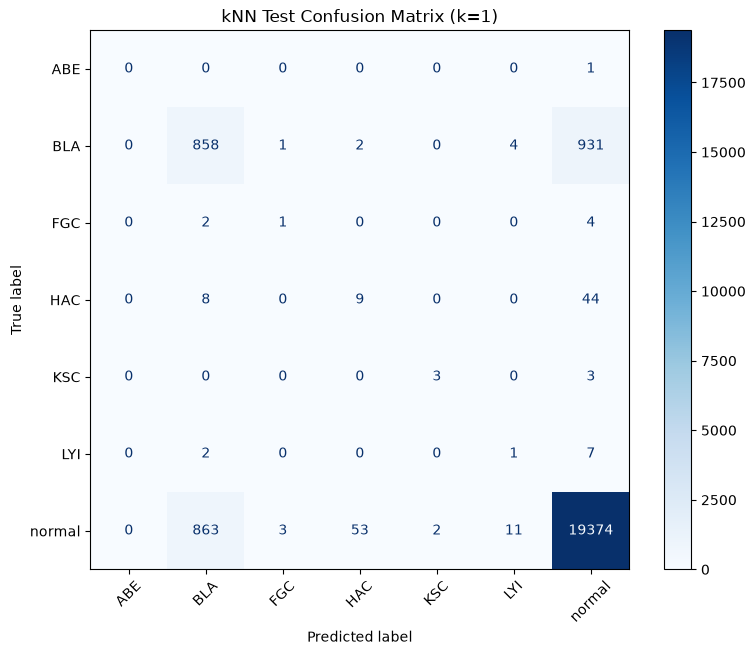

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Load saved embeddings
train_embeddings = np.load("embeddings.npy")
train_paths = np.load("paths.npy", allow_pickle=True)

test_embeddings = np.load("test_embeddings.npy")
test_paths = np.load("test_paths.npy", allow_pickle=True)

# Build labels from file paths
classes = ['ABE', 'BLA', 'FGC', 'HAC', 'KSC', 'LYI', 'normal']


train_df = pd.read_csv(os.path.join(ROOT, "DATA_PP/train.csv"))
test_df = pd.read_csv(os.path.join(ROOT, "DATA_PP/test.csv"))

def relative_path(path):
    return "DATA_PP/" + str(path).replace("\\", "/").split("DATA_PP/", 1)[-1]

train_label_map = dict(zip(train_df["filepath"], train_df["label"]))
test_label_map = dict(zip(test_df["filepath"], test_df["label"]))

train_labels = np.array([
    train_label_map[relative_path(p)] for p in train_paths
])

test_labels = np.array([
    test_label_map[relative_path(p)] for p in test_paths
])

class_to_idx = {c: i for i, c in enumerate(classes)}
train_y = np.array([class_to_idx[label] for label in train_labels])
test_y = np.array([class_to_idx[label] for label in test_labels])

# Best model from validation tuning
best_knn = KNeighborsClassifier(
    n_neighbors=1,
    metric="cosine",
    weights="uniform",
    algorithm="brute",
    n_jobs=-1
)
best_knn.fit(train_embeddings, train_y)

# Predict on test set
test_preds = best_knn.predict(test_embeddings)

# Metrics
test_acc = accuracy_score(test_y, test_preds)
test_macro_f1 = f1_score(test_y, test_preds, average="macro")

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print()
print("Classification Report:")
print(classification_report(test_y, test_preds, target_names=classes))

# Confusion matrix
cm = confusion_matrix(test_y, test_preds, labels=list(range(len(classes))))

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=True)
plt.title("kNN Test Confusion Matrix (k=1)")
plt.show()

In [29]:
import pandas as pd

knn_test_results = pd.DataFrame([
    {
        "Model": "ResNet50 + kNN",
        "Best k": 1,
        "Weighting": "uniform",
        "Test Accuracy": test_acc,
        "Test Macro F1": test_macro_f1
    }
])

knn_test_results

,Model,Best k,Weighting,Test Accuracy,Test Macro F1
0,ResNet50 + kNN,1,uniform,0.912516,0.338863


We selected k = 1 with uniform voting because it achieved the highest validation macro F1 of 0.3999. On the test set, the model achieved 91.25% accuracy and a macro F1 of 0.3389. Although overall accuracy remained similar, macro F1 decreased, showing that performance across the different classes was less consistent on the test set. The model performed well on normal cells but continued to struggle with rare abnormal classes, likely due in part to the large class imbalance in our dataset.